# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with **Gate 1 = GO**, **Gate 2 = GO (non-branching)** and
**Gate 3 = NA** the manifold is non-branching, so the branching-only correlation
and modules notebooks are not produced — this unconditional expression notebook
follows signatures directly, matching the Kürten 2021 non-branching precedent.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs
marking the ends of its trajectory. Per the **derive-don't-inherit** mandate we do
**not** inherit that pair: we score a candidate EMT-TF panel — the canonical
Snail/Zeb/Twist factors **plus the mesenchymal/neural-crest FOXC and PRRX
factors** — along *this* trajectory and let the data choose the most end-specific
factor at each end.

**I/O note.** §6 lists the expression step as reading `processed.h5ad` (Puram
inherits a *fixed* TF pair, so it needs only the embedding). Deriving the pair
data-driven instead requires the trajectory ends — pseudotime `t` and milestones —
which live in `signatures.h5ad`. We therefore read `signatures.h5ad` (same
deviation the Kürten non-branching precedent made); it is a superset of
`processed.h5ad` on the same cells, so no information is added beyond the
trajectory annotation. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir] * 6))
pth_data = os.path.join(pth, 'data')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name)

dataset: Chen2020_Head-and-Neck-5


### Load the rooted, signature-scored manifold
Keep the **native `X_umap`** — no re-layout. (Kürten swapped to a house linear
`X_umap_lin` because its manifold was an elongated strip; ours is a roundish cloud,
aspect ~1.4, and re-embedding an anisotropic compartment is the Kürten fork-4
failure mode. Raw coordinates keep this panel co-oriented with `samples.pdf`,
`manifold.pdf` and the signature panels — developmental origin left, Crest
terminus right.)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn = (t - t.min()) / (t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(), 2), '->', round(t.max(), 2),
      '| milestones', list(adata.obs['milestones'].cat.categories))

cells: 3635 | pseudotime 0.0 -> 9.75 | milestones ['Embryonic_origin', 'Crest_terminus']


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF we record the fraction of cells expressing it, its mean
expression in the early (root) vs late (terminus) pseudotime tercile, and its
Spearman correlation with pseudotime. The most negatively-correlated
sufficiently-expressed factor marks the root end; the most positively-correlated
marks the terminus. Factors below a **3 % expression floor** are too sparse to
overlay reliably.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]
    rho, _ = spearmanr(tn, x)
    rows.append((g, round((x > 0).mean(), 3), round(x[early].mean(), 3),
                 round(x[late].mean(), 3), round(rho, 3)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_early', 'mean_late', 'rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
below = df[df.frac_expr <= 0.03]['TF'].tolist()
above = df[df.frac_expr >  0.03]['TF'].tolist()
maxrho = df['rho_vs_t'].abs().max()
print(f'below 3%% detection floor: {below}; above floor: {above}.')
print(f'The two prototypical Snail/Twist factors SNAI1/TWIST1 sit below the floor; the '
      f'rest of the panel is expressed but weakly organised along pseudotime (max |rho| '
      f'= {maxrho:.3f} < 0.18). No EMT-TF is strongly end-polarised; the neural-crest/'
      f'mesenchymal PRRX/FOXC extension supplies the most end-specific factors.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
TWIST1      0.010       0.005      0.001    -0.031    EARLY(root)
 PRRX2      0.023       0.008      0.003    -0.029    EARLY(root)
 FOXC1      0.133       0.036      0.024     0.025    EARLY(root)
 FOXC2      0.043       0.015      0.006     0.027    EARLY(root)
 SNAI1      0.016       0.003      0.002     0.044    EARLY(root)
 SNAI2      0.246       0.070      0.058     0.065    EARLY(root)
  ZEB1      0.074       0.012      0.010     0.092    EARLY(root)
  ZEB2      0.130       0.026      0.022     0.101    EARLY(root)
TWIST2      0.060       0.008      0.016     0.115 LATE(terminus)
 PRRX1      0.626       0.327      0.432     0.171 LATE(terminus)

derived pair: FOXC1 (early/root) <-> PRRX1 (late/terminus)
below 3%% detection floor: ['TWIST1', 'PRRX2', 'SNAI1']; above floor: ['FOXC1', 'FOXC2', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST2', 'PRRX1'].
The two prototypical Snail/Twist factors SNAI1/TWIST1 sit below the floor; the r

### EMT-TF expression overlay (deliverable)
Reference (Puram-06) layout adapted to this dataset: a single **square** `(5, 5)`
UMAP (matching `samples.pdf` / `manifold.pdf` / the signature panels, since the
cloud is roundish, not a strip), raw coordinates (no axis inversion — co-oriented
with every other panel). The abundant late marker is drawn first so the sparser
early marker reads on top. Rather than overlaying every detected cell (`>0`), each
factor is thresholded at the **upper quartile** of expression among its expressing
cells, so only the strongest expressers show and the early (blue) / late (red)
regions separate.

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.323, 'PRRX1': 0.733} | cells shown: {'FOXC1': 121, 'PRRX1': 569}
saved expression.pdf
FOXC1: 13.3%% expressing; 121 shown (upper quartile), mean pseudotime of shown cells = 0.40 (all cells = 0.54)
PRRX1: 62.6%% expressing; 569 shown (upper quartile), mean pseudotime of shown cells = 0.56 (all cells = 0.54)
shown-cell pseudotime separation (late PRRX1 - early FOXC1) = +0.16


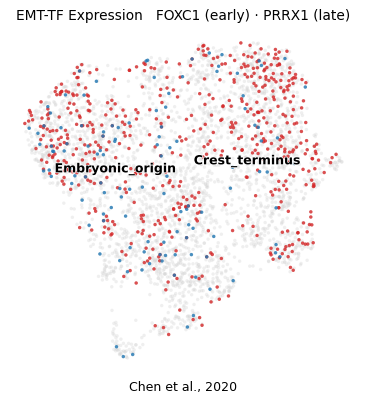

In [5]:
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()

# per-gene threshold = upper-quartile expression among expressing cells
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v > 0]
    thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):',
      {g: round(thr[g], 3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})

# draw abundant marker first, sparse on top
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf: 'tab:blue', late_tf: 'tab:red'}
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=30, alpha=.35, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=30, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=11)
ax.text(.5, -.05, 'Chen et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
print('saved expression.pdf')

for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g) > 0).mean() * 100:.1f}%% expressing; {int(m.sum())} shown '
          f'(upper quartile), mean pseudotime of shown cells = {tn[m].mean():.2f} '
          f'(all cells = {tn.mean():.2f})')
sep = tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()
print(f'shown-cell pseudotime separation (late {late_tf} - early {early_tf}) = {sep:+.2f}')